## Prawo Ohma

In [1]:
import os
import numpy as np
from PyLTSpice import SimCommander
from PyLTSpice import RawRead
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


BASE_DIR = "E:\\X\\Programming_Workspace\\Jupyter_Workspace\\LTSpice_Python_Automation\\Elektronika_Analogowa_AGH\\Podstawowe_Elementy_elektroniczne\\"
# === KONFIGURACJA ===
asc_file = BASE_DIR + "prawo_ohma\\prawo_Ohma.asc"
ltspice_path = "C:\\Users\\mateu\\AppData\\Local\\Programs\\ADI\\LTspice\\XVIIx64.exe"

# Debugging output
print(f"ASC File Path: {asc_file}")
print(f"LTspice Path: {ltspice_path}")

# === UTWORZENIE OBIEKTU SYMULACJI ===
sim = SimCommander(asc_file)
# Add a transient analysis command (e.g., simulate for 10ms)
sim.add_instructions(".tran 1m")
# === URUCHOMIENIE SYMULACJI ===
print("Uruchamiam symulację...")
sim.run()

# === SPRAWDZENIE PLIKU .RAW ===
# The .raw file is generated in the same directory as the .asc file
raw_file_path = os.path.splitext(asc_file)[0] + "_1.raw"
print(f"Sprawdzam plik .raw: {raw_file_path}")
if not os.path.exists(raw_file_path):
    raise RuntimeError(f"Plik .raw nie został wygenerowany: {raw_file_path}")

# === WYNIKI ===
raw = RawRead(raw_file_path)
signals = raw.get_trace_names()
print("Dostępne sygnały:", signals)

del sim


ASC File Path: E:\X\Programming_Workspace\Jupyter_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Podstawowe_Elementy_elektroniczne\prawo_ohma\prawo_Ohma.asc
LTspice Path: C:\Users\mateu\AppData\Local\Programs\ADI\LTspice\XVIIx64.exe
Uruchamiam symulację...
Sprawdzam plik .raw: E:\X\Programming_Workspace\Jupyter_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Podstawowe_Elementy_elektroniczne\prawo_ohma\prawo_Ohma_1.raw
Dostępne sygnały: ['time', 'V(n001)', 'V(n002)', 'I(R3)', 'I(R1)', 'I(R2)', 'I(V1)']


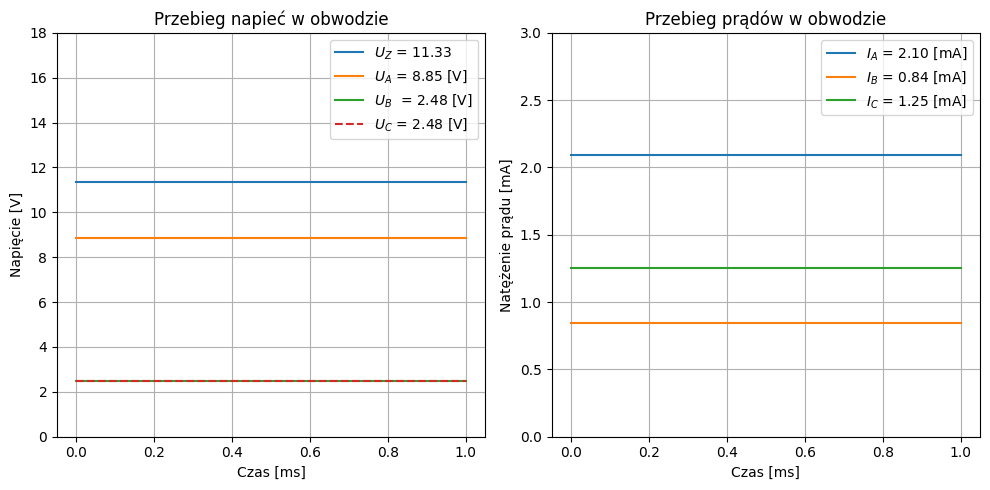

In [2]:
time = raw.get_trace("time").get_wave() * 1000

v1 = raw.get_trace("V(n001)").get_wave()
v2 = raw.get_trace("V(n002)").get_wave()
i1 = raw.get_trace("I(R1)").get_wave()  * -1000
i2 = raw.get_trace("I(R2)").get_wave() * -1000
i3 = raw.get_trace("I(R3)").get_wave() * -1000


# === RYSUJEMY WYKRES ===
fig,ax = plt.subplots(nrows = 1, ncols = 2, figsize=(10, 5))
ax[0].plot(time, v1, label=f"$U_Z$ = {np.mean(v1):.2f}")
ax[0].plot(time, v1-v2, label=f"$U_A$ = {np.mean(v1-v2):.2f} [V]", linestyle="-")
ax[0].plot(time, v2, label=f"$U_B$  = {np.mean(v2):.2f} [V]", linestyle="-")
ax[0].plot(time, v2, label=f"$U_C$ = {np.mean(v2):.2f} [V]", linestyle="--")

ax[0].set_xlabel("Czas [ms]")
ax[0].set_ylabel("Napięcie [V]")
ax[0].set_title("Przebieg napieć w obwodzie")
ax[0].grid(True)
ax[0].set_ylim(0,18)
ax[0].legend()


ax[1].plot(time, i1, label=f"$I_A$ = {np.mean(i1):.2f} [mA]", linestyle="-")
ax[1].plot(time, i2, label=f"$I_B$ = {np.mean(i2):.2f} [mA]", linestyle="-")
ax[1].plot(time, i3, label=f"$I_C$ = {np.mean(i3):.2f} [mA]", linestyle="-")

ax[1].set_xlabel("Czas [ms]")
ax[1].set_ylabel("Natężenie prądu [mA]")
ax[1].set_title("Przebieg prądów w obwodzie")
ax[1].grid(True)
ax[1].set_ylim(0,3)
ax[1].legend()

plt.tight_layout()
fig.savefig("prawo_ohma\\prawo_Ohma_graphs.png")


In [ ]:
def diode_circuit(asc_file, R):
    ltspice_path = "C:\\Users\\mateu\\AppData\\Local\\Programs\\ADI\\LTspice\\XVIIx64.exe"

    # === UTWORZENIE OBIEKTU SYMULACJI ===
    sim = SimCommander(asc_file)
    # Add a transient analysis command (e.g., simulate for 10ms)
    sim.add_instructions(".dc V1 0 12 0.1")
    sim.set_component_value("R1", R)

    # === URUCHOMIENIE SYMULACJI ===
    sim.run()

    # === SPRAWDZENIE PLIKU .RAW ===
    # The .raw file is generated in the same directory as the .asc file
    raw_file_path = os.path.splitext(asc_file)[0] + "_1.raw"
    if not os.path.exists(raw_file_path):
        raise RuntimeError(f"Plik .raw nie został wygenerowany: {raw_file_path}")

    # === WYNIKI ===
    raw = RawRead(raw_file_path)
    signals = raw.get_trace_names()
    print("Dostępne sygnały:", signals)
    return raw


def plot_diode_characteristic(i,v, df, name, title, x, up="U_p"):

    fig,ax = plt.subplots(figsize=(8, 6))
    ax.plot(v, i, label=f"$I_D \ zasymulowane$")
    ax.plot(df["UD"], df["I"], label=f"$I_D \ zmierzone$", marker="o")
    ax.set_xlabel("Napięcie [V]")
    ax.set_ylabel("Natężenie prądu [mA]")
    # ax.set_title(f"Charakterystyka {title}")
    ax.axvline(x = x, color = 'r', label = f'${up} = {np.abs(x)}$ [V]', linestyle='--')
    ax.legend()
    ax.grid(True)
 
    plt.show()
    fig.savefig(f"output\\{name}_graphs")

## Dioda prostownicza

In [4]:
name ="dioda_prostownicza"
asc_file = BASE_DIR + f"{name}\\{name}.asc"
R = "5078.3"

raw = diode_circuit(asc_file, R)

Dostępne sygnały: ['V1', 'V(n001)', 'V(n002)', 'I(V1)', 'I(D1)', 'I(R1)']


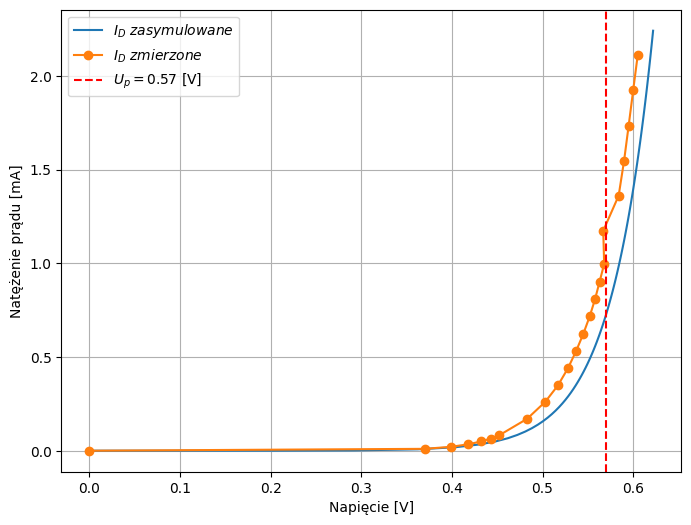

In [5]:
# LTSPICE simulation dla diody - 1N914
v = raw.get_trace("V(n002)").get_wave()
i = raw.get_trace("I(D1)").get_wave() * 1000

# Dane pomiarowe
df = pd.read_csv(f"{name}\\{name}.csv", sep=",")

# === RYSUJEMY WYKRES ===
plot_diode_characteristic(i, v, df, name, "diody prostowniczej", 0.57)


## Dioda LED

In [6]:
name ="dioda_led"
asc_file = BASE_DIR + f"{name}\\{name}.asc"
R = "6191.2"

raw = diode_circuit(asc_file, R)

Dostępne sygnały: ['V1', 'V(n001)', 'V(n002)', 'I(R1)', 'I(D1)', 'I(V1)']


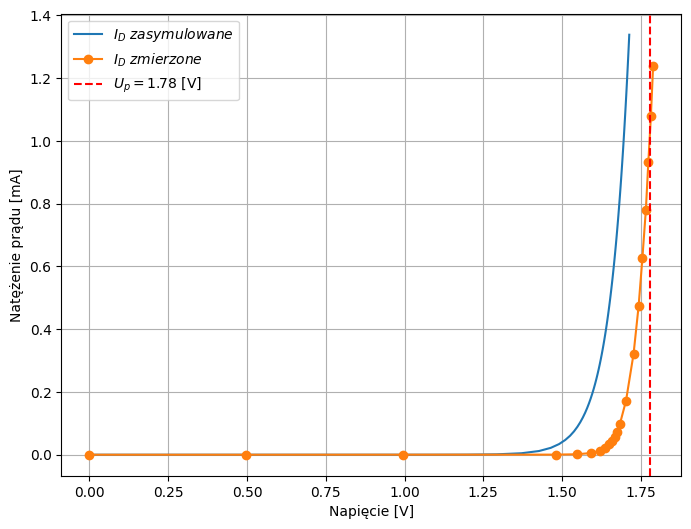

In [7]:
# SYmulacja dla diody LED # l12-red-100350
v = raw.get_trace("V(n002)").get_wave()
i = raw.get_trace("I(D1)").get_wave()*1000
n = 20
v = v[:-n]
i = i[:-n]
# Dane pomiarowe
df = pd.read_csv(f"{name}\\{name}.csv", sep=",")

plot_diode_characteristic(i, v, df, name, "czerwonej diody LED",  1.78)


## Dioda Zenera

In [8]:
name ="dioda_zener"
asc_file = BASE_DIR + f"{name}\\{name}.asc"
R = "982.8"

raw = diode_circuit(asc_file, R)

Dostępne sygnały: ['V1', 'V(n001)', 'V(n002)', 'I(R1)', 'I(D2)', 'I(V1)']


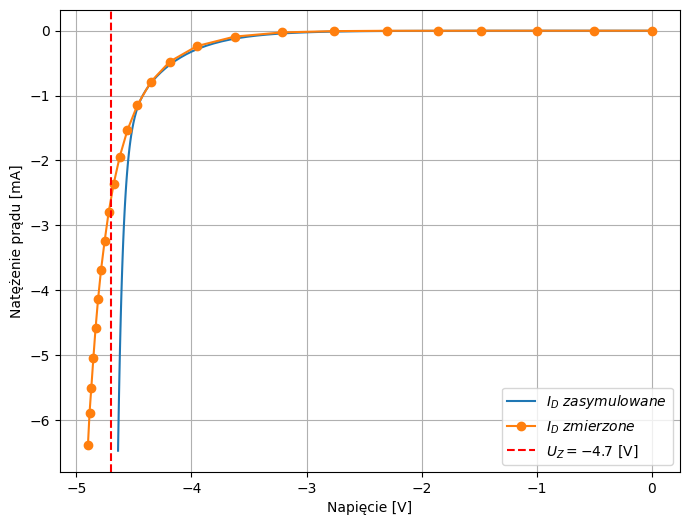

In [9]:
# Symulacja dla diody 1n750 - 4.7 V
v = raw.get_trace("V(n002)").get_wave() * -1
i = raw.get_trace("I(D2)").get_wave() * 1000
n = 10
v = v[:-n]
i = i[:-n]
# Dane pomiarowe
df = pd.read_csv(f"{name}\\{name}.csv", sep=",")

plot_diode_characteristic(i, v, df, name, "diody Zenera", -4.7, up="U_Z")

## Dioda Schottky

In [10]:
name ="dioda_schotky"
asc_file = BASE_DIR + f"{name}\\{name}.asc"
R = "6191.2"

raw = diode_circuit(asc_file, R)
raw = diode_circuit(asc_file, R)

Dostępne sygnały: ['V1', 'V(n001)', 'V(n002)', 'I(R1)', 'I(D2)', 'I(V1)']
Dostępne sygnały: ['V1', 'V(n001)', 'V(n002)', 'I(R1)', 'I(D2)', 'I(V1)']


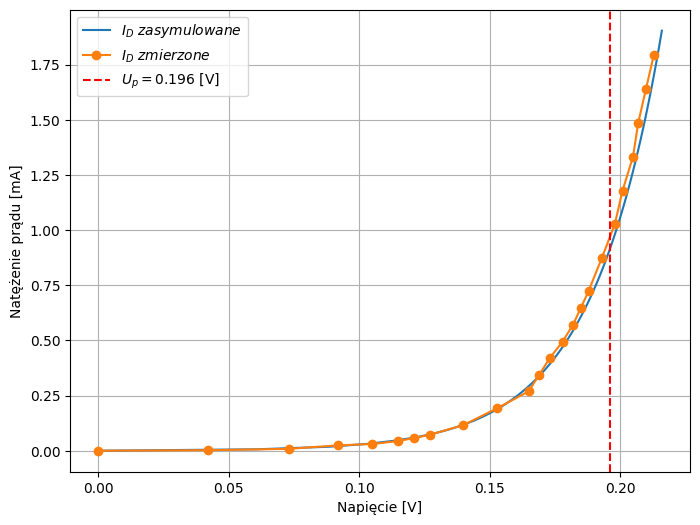

In [11]:
# Symulacja dla diody RB162MM-30
v = raw.get_trace("V(n002)").get_wave()
i = raw.get_trace("I(D2)").get_wave()*1000


name ="dioda_schotky"
# Dane pomiarowe
df = pd.read_csv(f"{name}\\{name}.csv", sep=",")

plot_diode_characteristic(i, v, df, name, "diody Schottkiego", 0.196)